# 06 Timestamps and metadata

This notebook gives every frame a timestamp, ties the session to UTC time and writes a draft episode_metadata record for each episode.

## 1. Setup

Loads the config and the reports from the earlier steps and checks the identity values.

In [1]:
# flags
ANCHOR_MODE = "manual"        # "auto", "manual" or "window_midpoint"
MANUAL_ROOT_TIME_S = 1105.8167   # root video second
MANUAL_SESSION_S = 1000     # session second that happens at that root second

import json, re, shutil, time, traceback, warnings, zipfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yaml, av, cv2
from tqdm import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)

# numbers from the earlier steps
FPS = 30.0
CHUNK = 5400
DEVS = ["head", "left", "right"]
SERIAL = {"head": "a45140", "left": "a60617", "right": "a59879"}
WINDOW_MAX_S = 42.3
ROOT_NAME = "video_20261011_200844.mp4"
ROOT_START_FALLBACK = "2026-10-11T14:38:44.654Z"
ROOT_END_FALLBACK = "2026-10-11T15:22:26Z"
SESSION_ZERO_FALLBACK = 7782913


def failed(e):
    print("step failed:", type(e).__name__, str(e)[:300])


ROOT = Path.cwd().parent
cfg_path = ROOT / "configs" / "config.yaml"
if not cfg_path.exists():
    raise FileNotFoundError("configs/config.yaml not found under " + str(ROOT) + ". open this notebook from the project notebooks folder.")

RAW = ROOT / "raw"
REP = ROOT / "reports"
INT = ROOT / "interim"
EPI = ROOT / "episodes"
for d in (REP, INT, EPI):
    d.mkdir(exist_ok=True)


def load_csv(name):
    p = REP / name
    if not p.exists():
        print("missing:", name)
        return None
    return pd.read_csv(p)


def load_json(name):
    p = REP / name
    if not p.exists():
        print("missing:", name)
        return {}
    return json.loads(p.read_text(encoding="utf-8"))


def find_key(obj, key):
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for v in obj.values():
            r = find_key(v, key)
            if r is not None:
                return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_key(v, key)
            if r is not None:
                return r
    return None


def clean_base(b):
    b = str(b)
    for ext in (".npz", ".mp4", ".txt"):
        if b.lower().endswith(ext):
            b = b[: -len(ext)]
    return b


def conv(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


# time helpers, everything in integer microseconds since the epoch
EPOCH = dt.datetime(1970, 1, 1, tzinfo=dt.timezone.utc)
IST = dt.timezone(dt.timedelta(hours=5, minutes=30))


def iso_to_us(s):
    d = dt.datetime.fromisoformat(str(s).replace("Z", "+00:00"))
    if d.tzinfo is None:
        d = d.replace(tzinfo=dt.timezone.utc)
    return int((d - EPOCH) // dt.timedelta(microseconds=1))


def us_to_dt(us, tz=dt.timezone.utc):
    return (EPOCH + dt.timedelta(microseconds=int(us))).astimezone(tz)


def round_ms(us):
    return (int(us) + 500) // 1000 * 1000


def us_to_iso(us, ms=True):
    if ms:
        us = round_ms(us)
    s = us_to_dt(us).strftime("%Y-%m-%dT%H:%M:%S.%f")
    return (s[:-3] if ms else s) + "Z"


def us_to_ist(us):
    return us_to_dt(round_ms(us), IST).strftime("%H:%M:%S.%f")[:-3]


manifest = load_csv("raw_manifest.csv")
episodes = load_csv("05_episodes.csv")
cut_list = load_csv("05_cut_list.csv")
summary05 = load_json("05_summary.json")
fit = load_csv("04_chunk_clock_fit.csv")
anchor04 = load_json("04_time_anchor.json")
imu_sum = load_csv("02_imu_file_summary.csv")
seam_df = load_csv("05_seam_continuity.csv")
summary03 = load_json("03_summary.json")

if episodes is not None:
    episodes = episodes.sort_values("start_s").reset_index(drop=True)
if fit is not None:
    fit["base"] = fit["base"].map(clean_base)
if manifest is not None:
    manifest["stem"] = manifest["rel_path"].map(lambda p: Path(str(p).replace("\\", "/")).stem)

for name, obj in [("manifest", manifest), ("episodes", episodes), ("cut_list", cut_list), ("chunk fit", fit),
                  ("imu summary", imu_sum), ("seam table", seam_df)]:
    print(name, "rows:", None if obj is None else len(obj))

v = find_key(summary05, "session_zero_us")
session_zero_us = int(v) if v is not None else SESSION_ZERO_FALLBACK
print("session_zero_us:", session_zero_us)

root_start_iso = anchor04.get("root_start_utc") or ROOT_START_FALLBACK
root_start_us = iso_to_us(root_start_iso)
root_end_us = iso_to_us(ROOT_END_FALLBACK)
print("root window:", us_to_iso(root_start_us), "to", us_to_iso(root_end_us))

# identity from config
cfg = yaml.safe_load(cfg_path.read_text(encoding="utf-8")) or {}
ident = cfg.get("identity") or {}


def pick(val, placeholder):
    s = "" if val is None else str(val).strip()
    if s == "" or s.upper() == "TBD":
        return placeholder, True
    return s, False


vendor, vendor_ph = pick(ident.get("vendor_name"), "vendorX")
operator, op_ph = pick(ident.get("operator_id"), "op01")
site, site_ph = pick(ident.get("site"), "site-unknown")
identity_placeholders = vendor_ph or op_ph or site_ph
print("config identity:", {k: ident.get(k) for k in ("vendor_name", "operator_id", "site")})
if identity_placeholders:
    print("WARNING: identity values are missing or TBD, using placeholders:", vendor, operator, site)


def id_part(s):
    return re.sub(r"[^A-Za-z0-9\-]", "-", str(s))


def make_id(date, k):
    return f"{id_part(vendor)}_{date}_{id_part(operator)}_{k + 1:06d}"


# shared results, filled by the later steps
ALL, FR, UT, CAP, META = {}, {}, {}, {}, {}
root_motion = None
dev_signal = None
anchor = None
SEAM8 = None

manifest rows: 94
episodes rows: 4
cut_list rows: 9
chunk fit rows: 45
imu summary rows: 47
seam table rows: 42
session_zero_us: 7782913
root window: 2026-10-11T14:38:44.654Z to 2026-10-11T15:22:26.000Z
config identity: {'vendor_name': 'TBD', 'operator_id': 'TBD', 'site': 'TBD'}


## 2. Per-frame timestamps

Maps each episode frame range to the source clips and collects the recorded timestamps and IMU rows. A smooth timestamp from the chunk model is computed for comparison.

In [2]:
FLAG_DUP, FLAG_GAP, FLAG_ZERO, FLAG_REP = 1, 2, 4, 8
GAP_US = 50000


def dev_rows(df, dev):
    return df[df["device"].astype(str).isin([dev, SERIAL[dev]])]


try:
    chunks = {d: dev_rows(fit, d).sort_values("rank").reset_index(drop=True) for d in DEVS}
    print("chunks per device:", {d: len(chunks[d]) for d in DEVS})
    if min(len(c) for c in chunks.values()) == 0:
        print("device values in fit table:", list(fit["device"].unique()))
    base_of_rank = {d: dict(zip(chunks[d]["rank"].astype(int), chunks[d]["base"])) for d in DEVS}

    imu_cache = {}

    def get_imu(base):
        if base not in imu_cache:
            z = np.load(INT / "imu" / (base + ".npz"))
            imu_cache[base] = {"t_us": z["t_us"].astype(np.int64), "acc": z["acc"].astype(np.float64),
                               "gyro": z["gyro"].astype(np.float64)}
        return imu_cache[base]

    ALL = {}
    for dev in DEVS:
        try:
            parts = {k: [] for k in ["t_us", "acc", "gyro", "gn", "rank", "local_i", "offset"]}
            for _, r in chunks[dev].iterrows():
                z = get_imu(r["base"])
                n = len(z["t_us"])
                i = np.arange(n)
                rk = int(r["rank"])
                parts["t_us"].append(z["t_us"])
                parts["acc"].append(z["acc"])
                parts["gyro"].append(z["gyro"])
                parts["gn"].append((rk - 1) * CHUNK + i)
                parts["rank"].append(np.full(n, rk))
                parts["local_i"].append(i)
                parts["offset"].append(np.full(n, float(r["offset_us"])))
            ALL[dev] = {k: np.concatenate(v) for k, v in parts.items()}
        except Exception as e:
            print("could not load imu for", dev)
            failed(e)
    print("imu rows loaded:", {d: len(ALL[d]["t_us"]) for d in ALL})
except Exception as e:
    failed(e)

prov_date = us_to_dt(root_start_us).strftime("%Y-%m-%d")
prov_ids = [make_id(prov_date, k) for k in range(len(episodes))]

FR = {}
rows = []
for k, ep in episodes.iterrows():
    outdir = EPI / prov_ids[k]
    outdir.mkdir(exist_ok=True)
    for dev in DEVS:
        try:
            a = ALL[dev]
            n0 = int(ep[dev + "_n_start"])
            n1 = int(ep[dev + "_n_stop_excl"])
            sel = np.where((a["gn"] >= n0) & (a["gn"] < n1))[0]
            if len(sel) != n1 - n0:
                print("ep", ep["id"], dev, "imu rows", len(sel), "but frame range has", n1 - n0)
            t_raw = a["t_us"][sel]
            acc = a["acc"][sel]
            gyro = a["gyro"][sel]
            gn = a["gn"][sel]
            rk = a["rank"][sel]
            li = a["local_i"][sel]
            t_smooth = a["offset"][sel] + li * 1e6 / FPS
            ranks_used = list(dict.fromkeys(rk.tolist()))
            bases = [base_of_rank[dev][r] for r in ranks_used]
            src = np.searchsorted(ranks_used, rk)

            # rows with a zero timestamp are filled by interpolation so the intervals stay usable
            t = t_raw.copy()
            bad = t <= 0
            if bad.any():
                good = np.where(~bad)[0]
                t[bad] = np.round(np.interp(np.where(bad)[0], good, t[good])).astype(np.int64)
                print("ep", ep["id"], dev, "rows with t_us <= 0 filled:", int(bad.sum()))

            d = np.diff(t)
            flags = np.zeros(len(t), dtype=np.uint8)
            flags[np.where(d == 0)[0] + 1] |= FLAG_DUP
            flags[np.where(d >= GAP_US)[0] + 1] |= FLAG_GAP
            zero = (acc == 0).all(axis=1) & (gyro == 0).all(axis=1)
            flags[zero] |= FLAG_ZERO
            rep = np.zeros(len(t), dtype=bool)
            rep[1:] = (acc[1:] == acc[:-1]).all(axis=1)
            flags[rep] |= FLAG_REP

            ts = (t - session_zero_us).astype(np.int64)
            maxdiff = float(np.abs(t - t_smooth).max() / 1000.0)
            np.savez(outdir / ("frames_" + dev + ".npz"), ts_session_us=ts, flags=flags, source_clip=src,
                     local_i=li, global_n=gn, acc=acc, gyro=gyro, source_clips=np.array(bases))
            FR[(k, dev)] = {"ts": ts, "flags": flags, "bases": bases, "ranks": ranks_used, "n0": n0, "n1": n1,
                            "maxdiff_ms": maxdiff}
            rows.append({"episode": str(ep["id"]), "device": dev, "frames": len(t),
                         "first_session_s": round(ts[0] / 1e6, 3), "last_session_s": round(ts[-1] / 1e6, 3),
                         "gaps_50ms": int((d >= GAP_US).sum()), "zero_intervals": int((d == 0).sum()),
                         "zero_imu_rows": int(zero.sum()), "repeated_acc": int(rep.sum()),
                         "backwards": int((d < 0).sum()), "max_diff_ms": round(maxdiff, 2), "n_clips": len(bases)})
        except Exception as e:
            print("episode", ep["id"], dev)
            failed(e)

try:
    ts_summary = pd.DataFrame(rows)
    ts_summary.to_csv(REP / "06_timestamp_summary.csv", index=False)
    print(ts_summary.drop(columns=["backwards", "n_clips"], errors="ignore").to_string(index=False))
except Exception as e:
    failed(e)

chunks per device: {'head': 15, 'left': 15, 'right': 15}
imu rows loaded: {'head': 77371, 'left': 76254, 'right': 76882}
episode device  frames  first_session_s  last_session_s  gaps_50ms  zero_intervals  zero_imu_rows  repeated_acc  max_diff_ms
   ep01   head   21240          272.023         980.002         10               0              0             0        23.53
   ep01   left   21239          272.022         980.003         11               0              0             0        46.64
   ep01  right   21239          272.023         980.002         11               0              1             0        53.78
   ep02   head    9390         1032.041        1344.999          4               0              0             0        20.36
   ep02   left    9390         1032.044        1345.003          4               0              1             0        19.89
   ep02  right    9390         1032.042        1345.002          4               0              0             0        20.37
   e

## 3. Seam 8 check

The seam table flags the left camera seam between rank 8 and 9, inside episode 3. This step looks at the picture change across that seam.

seam table columns: ['device', 'seam', 'diff_across', 'typical_diff', 'ratio']
frames read: 61 other differences: 59
seam diff 8.53, median of others 2.86, 99th percentile 9.45
seam value is the largest: no


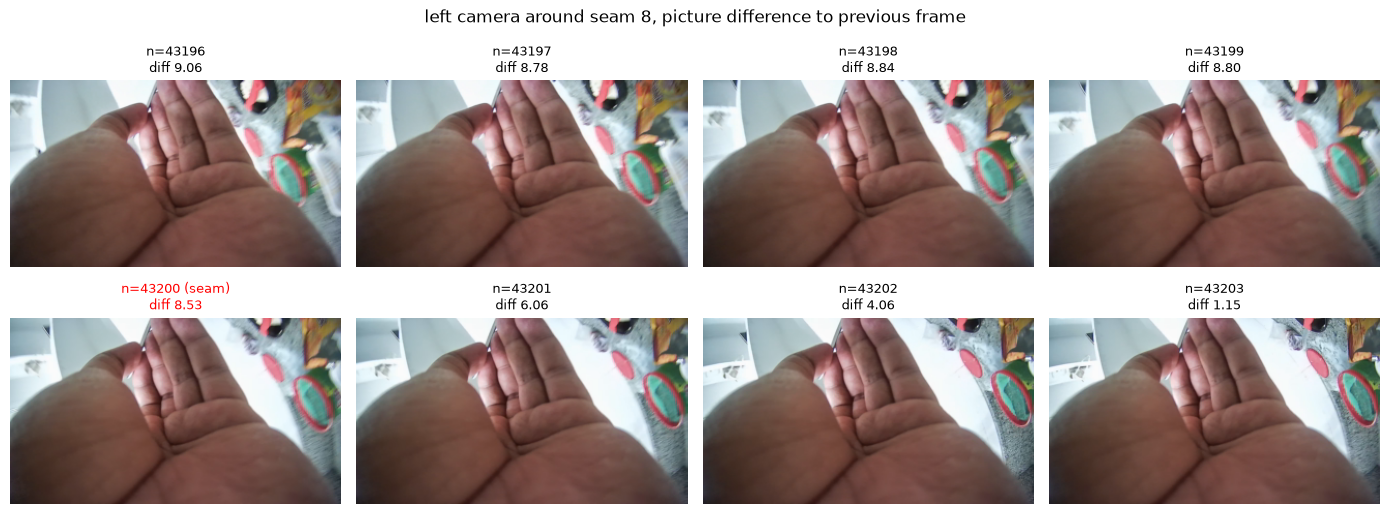

In [3]:
def small_gray(fr):
    try:
        a = fr.reformat(width=64, height=36, format="gray", interpolation="AREA").to_ndarray()
    except Exception:
        a = cv2.resize(fr.to_ndarray(format="gray"), (64, 36), interpolation=cv2.INTER_AREA)
    return a.astype(np.float32)


def resolve_path(rel):
    rel = str(rel).replace("\\", "/")
    for p in (ROOT / rel, RAW / rel):
        if p.exists():
            return p
    return None


def video_path_for(base):
    m = manifest[(manifest["stem"] == base) & manifest["rel_path"].str.lower().str.endswith(".mp4")]
    for rel in m["rel_path"]:
        p = resolve_path(rel)
        if p is not None:
            return p
    hits = list(RAW.rglob(base + ".mp4"))
    return hits[0] if hits else None


def read_frames(path, first_i, count, thumb_w=None, thumb_idx=None):
    # frames first_i .. first_i+count-1 of a clip, returns {index: (small gray, thumb)}
    out = {}
    with av.open(str(path)) as c:
        s = c.streams.video[0]
        s.thread_type = "AUTO"
        tb = float(s.time_base)
        fps = float(s.average_rate) if s.average_rate else FPS
        t0 = s.start_time or 0
        start_t = max(first_i / fps - 1.0, 0.0)
        if start_t > 0:
            c.seek(int(start_t / tb) + t0, stream=s, backward=True, any_frame=False)
        for fr in c.decode(s):
            if fr.pts is None:
                continue
            idx = int(round((fr.pts - t0) * tb * fps))
            if idx < first_i:
                continue
            if idx >= first_i + count:
                break
            thumb = None
            if thumb_w and (thumb_idx is None or idx in thumb_idx):
                h = int(round(thumb_w * fr.height / fr.width))
                thumb = fr.reformat(width=thumb_w, height=h, format="rgb24").to_ndarray()
            out[idx] = (small_gray(fr), thumb)
    return out


SEAM_RANK = 8
try:
    print("seam table columns:", list(seam_df.columns)[:12] if seam_df is not None else None)
    seam_n = SEAM_RANK * CHUNK
    ns = list(range(seam_n - 30, seam_n + 31))
    show = set(range(seam_n - 4, seam_n + 4))
    gray, thumbs = {}, {}
    for rk in sorted({n // CHUNK + 1 for n in ns}):
        loc = [n % CHUNK for n in ns if n // CHUNK + 1 == rk]
        p = video_path_for(base_of_rank["left"][rk])
        if p is None:
            raise FileNotFoundError("left video for rank " + str(rk) + " not found")
        want = {n % CHUNK for n in show if n // CHUNK + 1 == rk}
        got = read_frames(p, loc[0], len(loc), thumb_w=320, thumb_idx=want)
        for i, (g, th) in got.items():
            n = (rk - 1) * CHUNK + i
            gray[n] = g
            if th is not None:
                thumbs[n] = th
    missing = [n for n in ns if n not in gray]
    if missing:
        raise RuntimeError("could not read " + str(len(missing)) + " frames around the seam")
    diff = {n: float(np.abs(gray[n] - gray[n - 1]).mean()) for n in ns[1:]}
    seam_val = diff[seam_n]
    others = np.array([v for n, v in diff.items() if n != seam_n])
    med = float(np.median(others))
    p99 = float(np.percentile(others, 99))
    is_largest = bool(seam_val >= others.max())
    SEAM8 = {"seam_n": seam_n, "seam_diff": seam_val, "median_others": med, "p99_others": p99,
             "n_others": int(len(others)), "is_largest": is_largest}
    print("frames read:", len(ns), "other differences:", len(others))
    print("seam diff %.2f, median of others %.2f, 99th percentile %.2f" % (seam_val, med, p99))
    print("seam value is the largest:", "yes" if is_largest else "no")

    fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
    for ax, n in zip(axes.ravel(), sorted(show)):
        ax.imshow(thumbs[n])
        mark = " (seam)" if n == seam_n else ""
        ax.set_title("n=%d%s\ndiff %.2f" % (n, mark, diff[n]), fontsize=9, color="red" if n == seam_n else "black")
        ax.axis("off")
    fig.suptitle("left camera around seam 8, picture difference to previous frame")
    fig.tight_layout()
    fig.savefig(REP / "06_seam8_strip.png", dpi=120)
    plt.show()
except Exception as e:
    failed(e)

## 4. Root video activity signal

Decodes the whole phone video once and measures how much the picture changes in each second.

In [4]:
root_path = RAW / ROOT_NAME
root_cache = INT / "root_motion.npz"
try:
    if root_cache.exists():
        z = np.load(root_cache)
        root_motion = z["motion"]
        print("loaded cache:", len(root_motion), "seconds")
    else:
        sums = np.zeros(4000)
        cnts = np.zeros(4000)
        prev = None
        nfr = 0
        t0 = time.time()
        with av.open(str(root_path)) as c:
            s = c.streams.video[0]
            s.thread_type = "AUTO"
            est = int(s.frames) if s.frames else None
            avg = float(s.average_rate) if s.average_rate else 30.0
            for fr in tqdm(c.decode(s), total=est, mininterval=2):
                g = small_gray(fr)
                t = fr.time if fr.time is not None else nfr / avg
                sec = int(t)
                if sec >= len(sums):
                    sums = np.concatenate([sums, np.zeros(sec + 1000 - len(sums))])
                    cnts = np.concatenate([cnts, np.zeros(sec + 1000 - len(cnts))])
                if prev is not None:
                    sums[sec] += float(np.abs(g - prev).mean())
                    cnts[sec] += 1
                prev = g
                nfr += 1
        el = time.time() - t0
        last = int(np.where(cnts > 0)[0].max()) + 1
        sums, cnts = sums[:last], cnts[:last]
        m = np.where(cnts > 0, sums / np.maximum(cnts, 1), np.nan)
        idx = np.arange(last)
        ok = ~np.isnan(m)
        root_motion = np.interp(idx, idx[ok], m[ok])
        np.savez(root_cache, motion=root_motion, counts=cnts, n_frames=nfr)
        print("decoded %d frames in %.0f s (%.0f fps, %.1fx real time)" % (nfr, el, nfr / el, (last / el)))
        print("seconds:", last)
except Exception as e:
    failed(e)

loaded cache: 2622 seconds


## 5. Device activity signal

Takes the median gyro norm of each device per session second, z-scores them and averages the three.

In [5]:
try:
    def sec_signal(dev):
        a = ALL[dev]
        ok = (a["t_us"] > 0) & ~((a["gyro"] == 0).all(axis=1))
        sec = np.floor((a["t_us"][ok] - session_zero_us) / 1e6).astype(int)
        g = np.linalg.norm(a["gyro"][ok], axis=1)
        keep = sec >= 0
        return pd.Series(g[keep]).groupby(sec[keep]).median()

    sigs = {dev: sec_signal(dev) for dev in DEVS}
    n_sess = int(max(s.index.max() for s in sigs.values())) + 1
    zs = []
    for dev in DEVS:
        s = sigs[dev].reindex(range(n_sess)).interpolate(limit_area="inside")
        v = s.to_numpy(dtype=float)
        zs.append((v - np.nanmean(v)) / np.nanstd(v))
    dev_signal = np.nan_to_num(np.nanmean(np.vstack(zs), axis=0))
    SESS_LEN_S = float(max((ALL[d]["t_us"].max() - session_zero_us) / 1e6 for d in ALL))
    print("session seconds:", n_sess, " last timestamp at %.1f s" % SESS_LEN_S)
    print("signal range: %.2f to %.2f" % (dev_signal.min(), dev_signal.max()))
except Exception as e:
    failed(e)

session seconds: 2580  last timestamp at 2579.1 s
signal range: -0.99 to 6.89


## 6. Anchor estimate

Finds how many seconds after the root start the session clock starts. Lag is root time minus session time of the same moment.

mode manual, lag 105.82 s +- 1.50 s, session zero at 2026-10-11T14:40:30.471Z


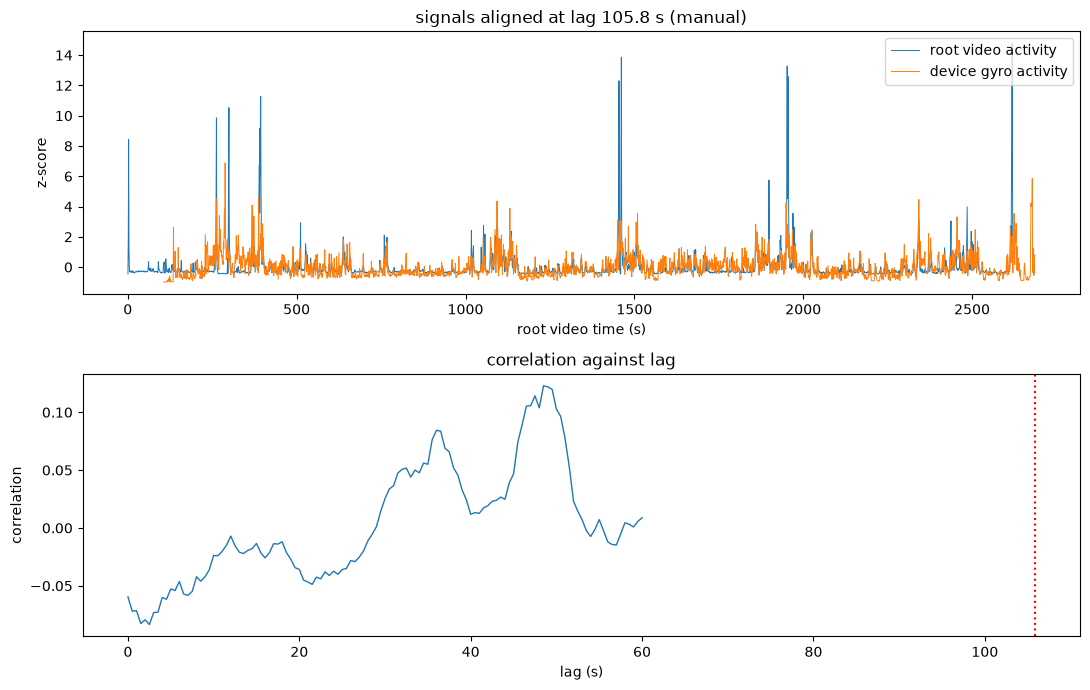

In [6]:
LAGS = np.arange(0, 60.0001, 0.5)
anchor = None
try:
    assumptions = ["lag = root video time minus session time of the same moment",
                   "root_start_utc taken from reports/04_time_anchor.json (creation_time is the end of the root video)",
                   "device signal = mean of z-scored per-second median gyro norm of head, left, right",
                   "root signal = per-second mean abs frame difference at 64x36 grey",
                   "both signals binned in 1 s, root signal interpolated at bin centres for half-second lags"]
    have_signals = root_motion is not None and dev_signal is not None
    mode = ANCHOR_MODE
    if mode == "auto" and not have_signals:
        print("signals missing, falling back to window_midpoint")
        mode = "window_midpoint"
    if mode == "manual" and not (isinstance(MANUAL_ROOT_TIME_S, (int, float)) and isinstance(MANUAL_SESSION_S, (int, float))):
        print("manual mode needs MANUAL_ROOT_TIME_S and MANUAL_SESSION_S, falling back to window_midpoint")
        mode = "window_midpoint"

    curve = None
    if have_signals:
        R, N = len(root_motion), len(dev_signal)
        centers = np.arange(R) + 0.5
        j = np.arange(N)
        tabs = []
        for lg in LAGS:
            tr = j + 0.5 + lg
            ok = (tr >= 0.5) & (tr <= R - 0.5)
            rv = np.interp(tr[ok], centers, root_motion)
            rv = rv - rv.mean()
            tabs.append((np.where(ok)[0], rv, float(np.sqrt((rv ** 2).sum()))))

        def corr_curve(sig):
            out = np.zeros(len(tabs))
            for q, (idx, rv, rn) in enumerate(tabs):
                x = sig[idx] - sig[idx].mean()
                den = float(np.sqrt((x ** 2).sum())) * rn
                out[q] = float(x @ rv) / den if den > 0 else 0.0
            return out

        curve = corr_curve(dev_signal)

    corr_peak = next_lag = next_corr = ctrl_max = ctrl_mean = None
    clear = False
    if mode == "auto":
        q = int(np.argmax(curve))
        lag = float(LAGS[q])
        corr_peak = float(curve[q])
        # next best local peak outside +-3 s
        peaks = [x for x in range(len(LAGS)) if abs(LAGS[x] - lag) > 3
                 and (x == 0 or curve[x] >= curve[x - 1]) and (x == len(LAGS) - 1 or curve[x] >= curve[x + 1])]
        if peaks:
            qn = max(peaks, key=lambda x: curve[x])
            next_lag, next_corr = float(LAGS[qn]), float(curve[qn])
        else:
            next_lag, next_corr = None, 0.0
        rng = np.random.default_rng(0)
        best = []
        for sh in rng.integers(300, 2001, 20):
            best.append(float(corr_curve(np.roll(dev_signal, int(sh))).max()))
        ctrl_max, ctrl_mean = float(np.max(best)), float(np.mean(best))
        clear = bool(corr_peak > 0 and corr_peak >= 1.2 * max(ctrl_max, next_corr))
        print("best lag %.1f s, correlation %.3f (overlap %d s)" % (lag, corr_peak, len(tabs[q][0])))
        print("next best peak outside +-3 s: %.3f at %s s" % (next_corr, next_lag))
        print("shuffle control: max %.3f, mean %.3f over 20 shifts" % (ctrl_max, ctrl_mean))
        print("peak clearly above control:", "yes" if clear else "no")
        uncertainty = 1.5 if clear else WINDOW_MAX_S / 2
        if not clear:
            print("WARNING: peak is not clear, keeping the best lag but uncertainty is the full window")
    elif mode == "manual":
        lag = float(MANUAL_ROOT_TIME_S - MANUAL_SESSION_S)
        uncertainty = 1.5
        assumptions.append("manual anchor: session second %s at root second %s" % (MANUAL_SESSION_S, MANUAL_ROOT_TIME_S))
    else:
        lag = WINDOW_MAX_S / 2
        uncertainty = WINDOW_MAX_S / 2
        assumptions.append("no signal match used, lag is the midpoint of the 0 to 42.3 s start window")

    session_zero_utc_us = root_start_us + int(round(lag * 1e6))
    anchor = {"mode": mode, "lag_s": lag, "correlation": corr_peak, "next_best_corr": next_corr,
              "next_best_lag_s": next_lag, "control_max": ctrl_max, "control_mean": ctrl_mean,
              "peak_clearly_above_control": clear if mode == "auto" else None, "uncertainty_s": uncertainty,
              "session_zero_utc": us_to_iso(session_zero_utc_us), "session_zero_utc_us": session_zero_utc_us,
              "assumptions": assumptions}
    print("mode %s, lag %.2f s +- %.2f s, session zero at %s" % (mode, lag, uncertainty, anchor["session_zero_utc"]))
    (REP / "06_anchor_estimate.json").write_text(json.dumps(anchor, indent=2, default=conv), encoding="utf-8")

    if have_signals:
        fig, axes = plt.subplots(2, 1, figsize=(11, 7))
        zr = (root_motion - root_motion.mean()) / root_motion.std()
        axes[0].plot(np.arange(len(zr)) + 0.5, zr, lw=0.7, label="root video activity")
        axes[0].plot(np.arange(len(dev_signal)) + 0.5 + lag, dev_signal, lw=0.7, label="device gyro activity")
        axes[0].set_xlabel("root video time (s)")
        axes[0].set_ylabel("z-score")
        axes[0].set_title("signals aligned at lag %.1f s (%s)" % (lag, mode))
        axes[0].legend(loc="upper right")
        axes[1].plot(LAGS, curve, lw=1)
        if mode == "auto":
            axes[1].plot([lag], [corr_peak], "ro", label="peak")
            axes[1].axhline(ctrl_max, color="gray", ls="--", label="shuffle control max")
            axes[1].legend()
        else:
            axes[1].axvline(lag, color="r", ls=":")
        axes[1].set_xlabel("lag (s)")
        axes[1].set_ylabel("correlation")
        axes[1].set_title("correlation against lag")
        fig.tight_layout()
        fig.savefig(REP / "06_activity_sync.png", dpi=120)
        plt.show()
except Exception as e:
    failed(e)

## 7. Match sheet

Puts the head frame and the root frame side by side for six moments so the match can be checked by eye.

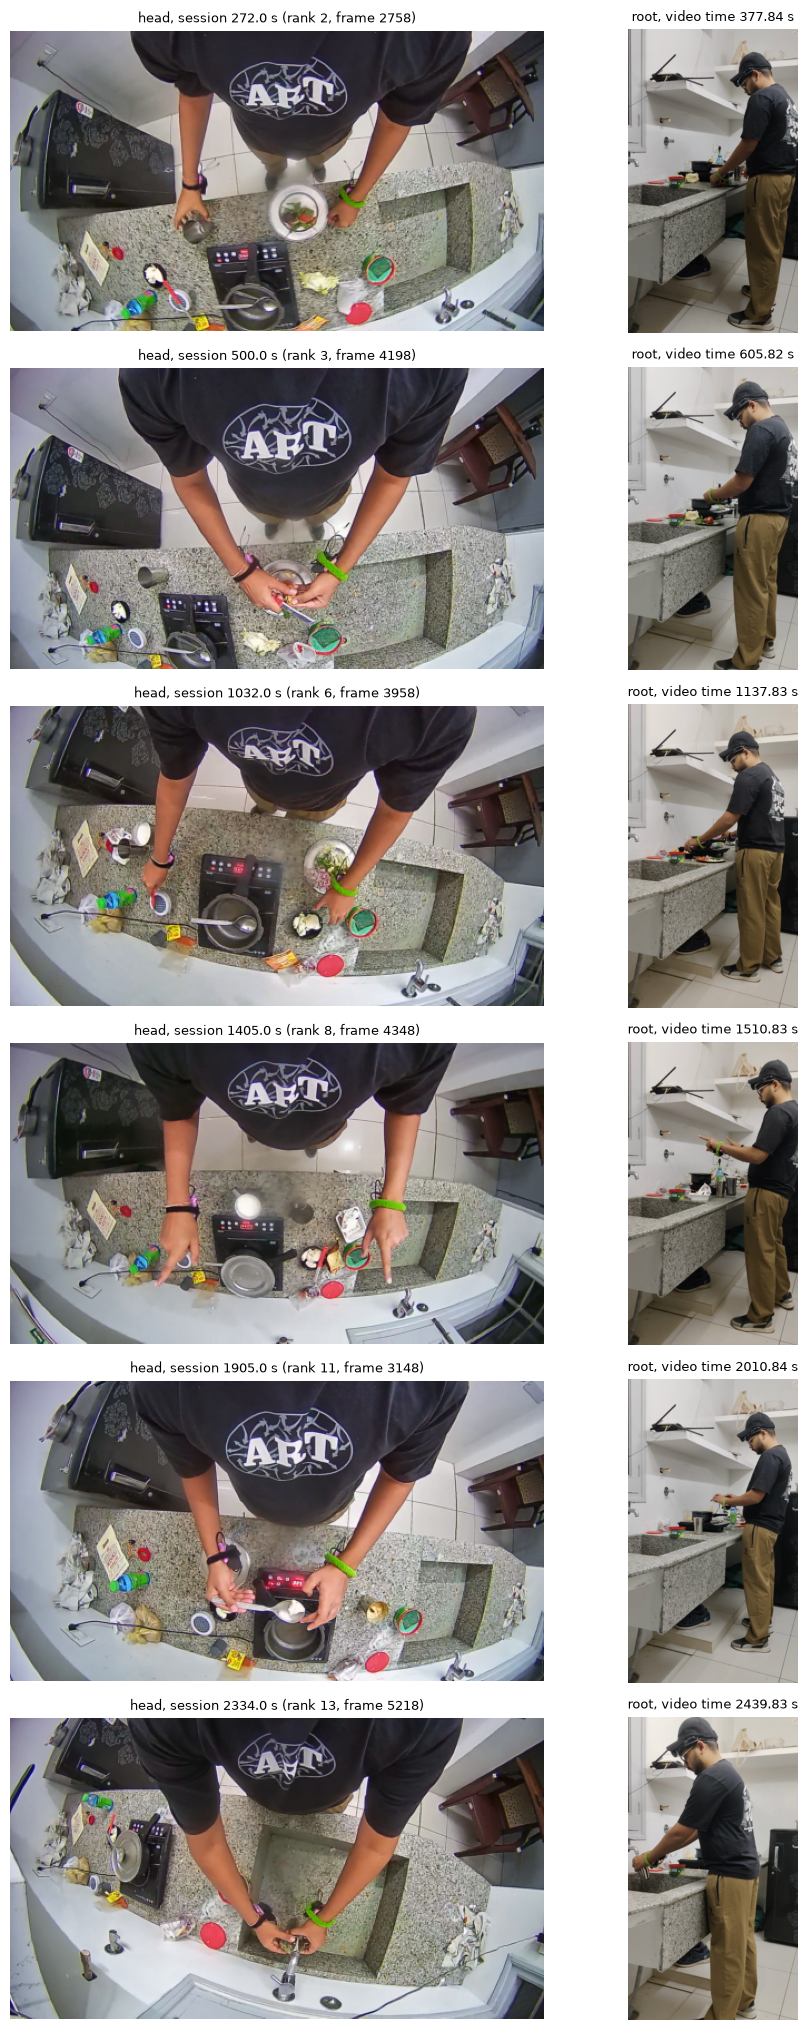

In [7]:
SESSION_SECS = [272, 500, 1032, 1405, 1905, 2334]
ROOT_ROT = cv2.ROTATE_90_CLOCKWISE   # root rotation metadata is -90, so the frame is turned clockwise to be upright
THUMB_W = 480


def root_frame_at(path, t, w):
    with av.open(str(path)) as c:
        s = c.streams.video[0]
        s.thread_type = "AUTO"
        tb = float(s.time_base)
        c.seek(int(max(t - 3, 0) / tb), stream=s, backward=True, any_frame=False)
        for fr in c.decode(s):
            if fr.time is None or fr.time < t:
                continue
            h = int(round(w * fr.height / fr.width))
            return fr.reformat(width=w, height=h, format="rgb24").to_ndarray(), float(fr.time)
    return None, None


try:
    lag_used = anchor["lag_s"]
    a = ALL["head"]
    okh = a["t_us"] > 0
    fig, axes = plt.subplots(len(SESSION_SECS), 2, figsize=(10, 3.4 * len(SESSION_SECS)))
    for row, s in enumerate(SESSION_SECS):
        try:
            target = session_zero_us + s * 1e6
            cand = np.where(okh)[0]
            kk = cand[np.argmin(np.abs(a["t_us"][cand] - target))]
            rk, li = int(a["rank"][kk]), int(a["local_i"][kk])
            hp = video_path_for(base_of_rank["head"][rk])
            got = read_frames(hp, li, 1, thumb_w=THUMB_W)
            head_img = cv2.rotate(got[li][1], cv2.ROTATE_180)
            troot = s + lag_used
            rimg, rt = root_frame_at(root_path, troot, THUMB_W)
            rimg = cv2.rotate(rimg, ROOT_ROT)
            axes[row, 0].imshow(head_img)
            axes[row, 0].set_title("head, session %.1f s (rank %d, frame %d)" % ((a["t_us"][kk] - session_zero_us) / 1e6, rk, li), fontsize=9)
            axes[row, 1].imshow(rimg)
            axes[row, 1].set_title("root, video time %.2f s" % rt, fontsize=9)
        except Exception as e:
            print("row for session second", s)
            failed(e)
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")
    fig.tight_layout()
    fig.savefig(REP / "06_match_sheet.png", dpi=100)
    plt.show()
except Exception as e:
    failed(e)

## 8. UTC mapping

Converts the session timestamps to UTC with the anchor and checks that every episode lies inside the root recording.

In [8]:
try:
    sz = anchor["session_zero_utc_us"]
    unc = anchor["uncertainty_s"]
    UT, CAP = {}, {}
    rows = []
    for k, ep in episodes.iterrows():
        for dev in DEVS:
            ts = FR[(k, dev)]["ts"]
            UT[(k, dev)] = (sz + int(ts[0]), sz + int(ts[-1]))
        h0, h1 = UT[(k, "head")]
        stop_us = h1 + int(round(1e6 / FPS))
        CAP[k] = (us_to_iso(h0), us_to_iso(stop_us), round_ms(h0), round_ms(stop_us))
        first_all = min(UT[(k, d)][0] for d in DEVS)
        last_all = max(UT[(k, d)][1] for d in DEVS) + int(round(1e6 / FPS))
        inside = bool(first_all >= root_start_us and last_all <= root_end_us)
        rows.append({"episode": str(ep["id"]), "start_utc": CAP[k][0][11:], "stop_utc": CAP[k][1][11:],
                     "start_ist": us_to_ist(h0), "stop_ist": us_to_ist(stop_us), "uncertainty_s": unc,
                     "inside_root": inside})
    utc_table = pd.DataFrame(rows)
    print(utc_table.to_string(index=False))
    print("root recording window:", us_to_iso(root_start_us), "to", us_to_iso(root_end_us))
    print("all episodes inside the root recording:", bool(utc_table["inside_root"].all()))
except Exception as e:
    failed(e)

episode     start_utc      stop_utc    start_ist     stop_ist  uncertainty_s  inside_root
   ep01 14:45:02.494Z 14:56:50.506Z 20:15:02.494 20:26:50.506            1.5         True
   ep02 14:57:42.512Z 15:02:55.503Z 20:27:42.512 20:32:55.503            1.5         True
   ep03 15:03:55.514Z 15:09:42.486Z 20:33:55.514 20:39:42.486            1.5         True
   ep04 15:12:15.516Z 15:22:15.511Z 20:42:15.516 20:52:15.511            1.5         True
root recording window: 2026-10-11T14:38:44.654Z to 2026-10-11T15:22:26.000Z
all episodes inside the root recording: True


## 9. Episode ids and metadata drafts

Builds the episode ids and writes a draft episode_metadata.json for each episode, plus a version where every value is a string.

In [9]:
CAM = {"cam_high": {"role": "egocentric", "resolution": [1920, 1080], "is_pose_source": True},
       "cam_left_wrist": {"role": "left_wrist", "resolution": [1920, 1080]},
       "cam_right_wrist": {"role": "right_wrist", "resolution": [1920, 1080]}}
RIG = {"description": "chest-mounted egocentric camera looking down (raw image rotated 180 degrees) + left and right wrist cameras looking at the palms, 1920x1080 at 30 fps, IMU on every device"}


def short_hash(x):
    if isinstance(x, dict):
        return {k: short_hash(v) for k, v in x.items()}
    if isinstance(x, list):
        return [short_hash(v) for v in x]
    if isinstance(x, str) and re.fullmatch(r"[0-9a-f]{64}", x):
        return x[:12] + "..."
    return x


try:
    serial = dict(SERIAL)
    for dev in DEVS:
        r = dev_rows(manifest, dev)
        if len(r) and "serial" in r.columns:
            serial[dev] = str(r["serial"].iloc[0])
    META, final_ids = {}, []
    for k, ep in episodes.iterrows():
        date = us_to_dt(UT[(k, "head")][0]).strftime("%Y-%m-%d")
        eid = make_id(date, k)
        final_ids.append(eid)
        outdir = EPI / eid
        outdir.mkdir(exist_ok=True)
        if prov_ids[k] != eid:
            old = EPI / prov_ids[k]
            for f in (list(old.glob("*")) if old.exists() else []):
                dest = outdir / f.name
                if dest.exists():
                    dest.unlink()
                shutil.move(str(f), str(dest))
            try:
                old.rmdir()
            except OSError:
                pass
            print("moved frame files from", prov_ids[k], "to", eid)

        nhead = len(FR[(k, "head")]["ts"])
        tid = ep["task_id"]
        try:
            tid = str(int(tid)).zfill(4)
        except (ValueError, TypeError):
            tid = str(tid)
        prov_files, clip_ids, ranges, nframes, flagsum, seams = {}, {}, {}, {}, {}, {}
        for dev in DEVS:
            f = FR[(k, dev)]
            clip_ids[dev] = f["bases"]
            files = []
            for b in f["bases"]:
                m = manifest[manifest["stem"] == b]
                if len(m) < 2:
                    print("note: only", len(m), "manifest rows for", b)
                for r in m.itertuples():
                    files.append({"rel_path": str(r.rel_path).replace("\\", "/"), "sha256": str(r.sha256)})
            prov_files[dev] = files
            ranges[dev] = {"start_rank": int(ep[dev + "_start_rank"]), "start_i": int(ep[dev + "_start_i"]),
                           "stop_rank": int(ep[dev + "_stop_rank"]), "stop_i_excl": int(ep[dev + "_stop_i_excl"]),
                           "n_start": f["n0"], "n_stop_excl": f["n1"]}
            nframes[dev] = len(f["ts"])
            fl = f["flags"]
            flagsum[dev] = {"duplicate_timestamp": int(((fl & FLAG_DUP) > 0).sum()),
                            "gap_50ms_or_more": int(((fl & FLAG_GAP) > 0).sum()),
                            "all_zero_imu": int(((fl & FLAG_ZERO) > 0).sum()),
                            "repeated_acc": int(((fl & FLAG_REP) > 0).sum()),
                            "max_diff_to_smooth_ms": round(f["maxdiff_ms"], 2)}
            seams[dev] = [s for s in range(1, 15) if f["n0"] < s * CHUNK < f["n1"]]
        meta = {"episode_id": eid, "capture_start_iso": CAP[k][0], "capture_stop_iso": CAP[k][1],
                "fps": 30.0, "fps_rational": "30/1", "duration_sec": nhead / 30, "max_timesteps": nhead,
                "rig": RIG, "cameras": CAM, "user_id": operator, "task_id": tid, "task_name": str(ep["task_name"]),
                "language_instruction": None, "spans": None, "pose_modality": None, "coverage": None,
                "pending": ["P7", "P8"],
                "episode_tags": [vendor, "egocentric", "hand_pose"],
                "source_provenance": {
                    "site": site, "operator": operator, "session_id": "20261011_200844",
                    "source_clip_ids": clip_ids, "device_serials": serial, "source_files": prov_files,
                    "time_anchor": {"mode": anchor["mode"], "lag_s": anchor["lag_s"],
                                    "uncertainty_s": anchor["uncertainty_s"], "root_file": ROOT_NAME},
                    "frame_ranges": ranges, "frames": nframes, "timestamp_flags": flagsum,
                    "seams_crossed": seams, "identity_placeholders": bool(identity_placeholders)}}
        META[k] = meta
        (outdir / "episode_metadata_draft.json").write_text(json.dumps(meta, indent=2, default=conv), encoding="utf-8")
        strs = {key: (v if isinstance(v, str) else json.dumps(v, default=conv)) for key, v in meta.items()}
        (outdir / "episode_metadata_mcap_strings.json").write_text(json.dumps(strs, indent=2), encoding="utf-8")
    print("episode ids:", final_ids)
    print("draft of episode 1 (hashes shortened for printing):")
    print(json.dumps(short_hash(META[0]), indent=2, default=conv))
except Exception as e:
    failed(e)

episode ids: ['vendorX_2026-10-11_op01_000001', 'vendorX_2026-10-11_op01_000002', 'vendorX_2026-10-11_op01_000003', 'vendorX_2026-10-11_op01_000004']
draft of episode 1 (hashes shortened for printing):
{
  "episode_id": "vendorX_2026-10-11_op01_000001",
  "capture_start_iso": "2026-10-11T14:45:02.494Z",
  "capture_stop_iso": "2026-10-11T14:56:50.506Z",
  "fps": 30.0,
  "fps_rational": "30/1",
  "duration_sec": 708.0,
  "max_timesteps": 21240,
  "rig": {
    "description": "chest-mounted egocentric camera looking down (raw image rotated 180 degrees) + left and right wrist cameras looking at the palms, 1920x1080 at 30 fps, IMU on every device"
  },
  "cameras": {
    "cam_high": {
      "role": "egocentric",
      "resolution": [
        1920,
        1080
      ],
      "is_pose_source": true
    },
    "cam_left_wrist": {
      "role": "left_wrist",
      "resolution": [
        1920,
        1080
      ]
    },
    "cam_right_wrist": {
      "role": "right_wrist",
      "resolution": 

## 10. Completeness check

Checks the 17 required keys for every episode. A key is filled, pending (waiting for a later phase) or placeholder (built from placeholder identity values).

In [10]:
REQUIRED = ["episode_id", "capture_start_iso", "capture_stop_iso", "fps", "duration_sec", "max_timesteps", "rig",
            "cameras", "user_id", "task_id", "task_name", "language_instruction", "spans", "pose_modality",
            "coverage", "episode_tags", "source_provenance"]
try:
    ph = {"episode_id": vendor_ph or op_ph, "user_id": op_ph, "episode_tags": vendor_ph,
          "source_provenance": vendor_ph or op_ph or site_ph}
    rows = []
    for k, meta in META.items():
        row = {"episode_id": meta["episode_id"]}
        for key in REQUIRED:
            val = meta.get(key)
            if val is None:
                row[key] = "pending"
            elif val == "" or val == [] or val == {}:
                row[key] = "missing"
            elif ph.get(key):
                row[key] = "placeholder"
            else:
                row[key] = "filled"
        rows.append(row)
    status = pd.DataFrame(rows)
    status.to_csv(REP / "06_metadata_status.csv", index=False)
    print(status.set_index("episode_id").T.to_string())
except Exception as e:
    failed(e)

episode_id            placeholder  placeholder  placeholder  placeholder
capture_start_iso          filled       filled       filled       filled
capture_stop_iso           filled       filled       filled       filled
fps                        filled       filled       filled       filled
duration_sec               filled       filled       filled       filled
max_timesteps              filled       filled       filled       filled
rig                        filled       filled       filled       filled
cameras                    filled       filled       filled       filled
user_id               placeholder  placeholder  placeholder  placeholder
task_id                    filled       filled       filled       filled
task_name                  filled       filled       filled       filled
language_instruction      pending      pending      pending      pending
spans                     pending      pending      pending      pending
pose_modality             pending      pending     

## 11. Hypothesis tests

Simple checks on the anchor, the timestamps and the metadata. INFO rows are only reported.

In [11]:
tests = []


def run_test(tid, hyp, fn):
    try:
        measured, result = fn()
    except Exception as e:
        measured, result = "not computed: " + str(e)[:60], "FLAG"
    tests.append({"id": tid, "hypothesis": hyp, "measured": measured, "result": result})


def t_m1():
    if anchor["mode"] != "auto":
        return "mode is " + anchor["mode"] + ", no peak computed", "INFO"
    return ("peak %.3f, control max %.3f, next peak %.3f, clear: %s" % (
        anchor["correlation"], anchor["control_max"], anchor["next_best_corr"],
        "yes" if anchor["peak_clearly_above_control"] else "no")), "INFO"


def t_m2():
    lg = anchor["lag_s"]
    return "lag %.2f s" % lg, "PASS" if 0 <= lg <= WINDOW_MAX_S else "FLAG"


def t_m3():
    dup = sum(int(((FR[x]["flags"] & FLAG_DUP) > 0).sum()) for x in FR)
    gap = sum(int(((FR[x]["flags"] & FLAG_GAP) > 0).sum()) for x in FR)
    return "%d duplicate timestamps, %d skipped slots (all episodes and devices)" % (dup, gap), "INFO"


def t_m4():
    worst = max(FR[x]["maxdiff_ms"] for x in FR)
    return "max %.1f ms" % worst, "PASS" if worst <= 70 else "FLAG"


def t_m5():
    spread = 0
    for k in episodes.index:
        n = [len(FR[(k, d)]["ts"]) for d in DEVS]
        spread = max(spread, max(n) - min(n))
    return "max difference %d frames" % spread, "PASS" if spread <= 1 else "FLAG"


def t_m6():
    ids = [m["episode_id"] for m in META.values()]
    return "%d ids, %d unique" % (len(ids), len(set(ids))), "PASS" if len(ids) == len(set(ids)) and ids else "FLAG"


def t_m7():
    bad = []
    for k in episodes.index:
        first = min(UT[(k, d)][0] for d in DEVS)
        last = max(UT[(k, d)][1] for d in DEVS) + int(round(1e6 / FPS))
        if first < root_start_us or last > root_end_us:
            bad.append(str(episodes.loc[k, "id"]))
    return ("outside: " + str(bad)) if bad else "all inside", "FLAG" if bad else "PASS"


def t_m8():
    bad = 0
    for k, m in META.items():
        p = EPI / m["episode_id"] / "episode_metadata_draft.json"
        d = json.loads(p.read_text(encoding="utf-8"))
        if abs(d["duration_sec"] - d["max_timesteps"] / 30) > 1e-9:
            bad += 1
    return "%d of %d differ" % (bad, len(META)), "PASS" if bad == 0 and META else "FLAG"


def t_m9():
    return ("yes" if identity_placeholders else "no") + " (vendor %s, operator %s, site %s)" % (vendor, operator, site), "INFO"


def t_m10():
    s = SEAM8
    return "seam %.2f vs median %.2f (x%.1f), p99 %.2f, largest: %s" % (
        s["seam_diff"], s["median_others"], s["seam_diff"] / max(s["median_others"], 1e-9), s["p99_others"],
        "yes" if s["is_largest"] else "no"), "INFO"


run_test("M1", "anchor peak is clearly above the shuffle control", t_m1)
run_test("M2", "lag lies within 0 to 42.3 s", t_m2)
run_test("M3", "duplicate timestamps and skipped slots inside the episodes", t_m3)
run_test("M4", "recorded and smooth timestamps differ by at most 70 ms", t_m4)
run_test("M5", "frame counts differ by at most 1 between devices", t_m5)
run_test("M6", "episode_id values are unique", t_m6)
run_test("M7", "every episode lies inside the root recording window", t_m7)
run_test("M8", "duration_sec equals max_timesteps / 30", t_m8)
run_test("M9", "identity values are placeholders", t_m9)
run_test("M10", "seam 8 picture difference relative to the others", t_m10)

try:
    hyp = pd.DataFrame(tests)
    hyp.to_csv(REP / "06_hypothesis_check.csv", index=False)
    pd.set_option("display.max_colwidth", 80)
    print(hyp.to_string(index=False))
except Exception as e:
    failed(e)

 id                                                 hypothesis                                                            measured result
 M1           anchor peak is clearly above the shuffle control                                    mode is manual, no peak computed   INFO
 M2                                lag lies within 0 to 42.3 s                                                        lag 105.82 s   FLAG
 M3 duplicate timestamps and skipped slots inside the episodes 4 duplicate timestamps, 87 skipped slots (all episodes and devices)   INFO
 M4     recorded and smooth timestamps differ by at most 70 ms                                                        max 101.0 ms   FLAG
 M5           frame counts differ by at most 1 between devices                                             max difference 1 frames   PASS
 M6                               episode_id values are unique                                                     4 ids, 4 unique   PASS
 M7        every episode lies insi

## 12. Episode clock figure

Draws the episodes on the real clock in IST, with the discarded parts shaded and the root recording as a bar.

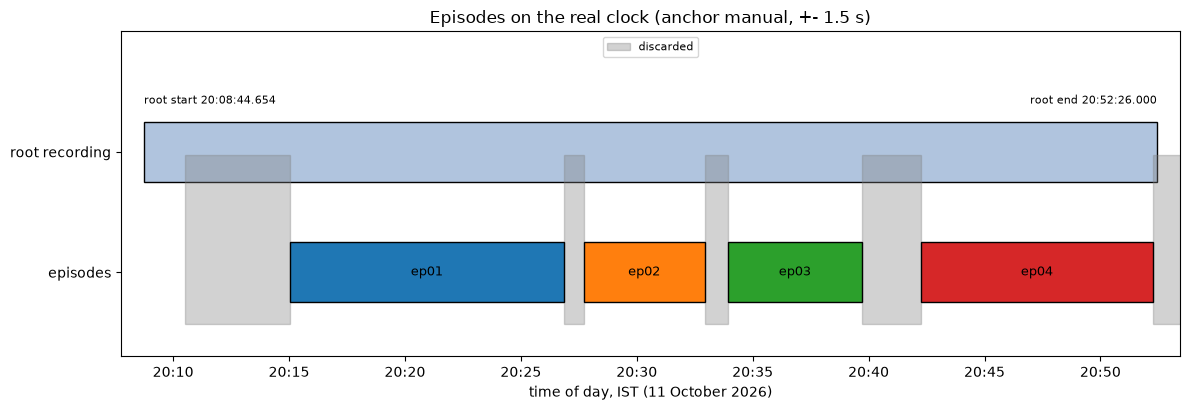

In [12]:
def to_num(us):
    return mdates.date2num(us_to_dt(us, IST).replace(tzinfo=None))


try:
    sz = anchor["session_zero_utc_us"]
    fig, ax = plt.subplots(figsize=(12, 4.2))
    # root bar
    ax.barh(2, to_num(root_end_us) - to_num(root_start_us), left=to_num(root_start_us), height=0.5, color="lightsteelblue", edgecolor="k")
    ax.text(to_num(root_start_us), 2.4, "root start " + us_to_ist(root_start_us), fontsize=8, ha="left")
    ax.text(to_num(root_end_us), 2.4, "root end " + us_to_ist(root_end_us), fontsize=8, ha="right")
    # discarded parts of the session
    edges = [0.0] + [x for _, r in episodes.iterrows() for x in (float(r["start_s"]), float(r["stop_s"]))] + [SESS_LEN_S]
    first = True
    for a0, a1 in zip(edges[0::2], edges[1::2]):
        if a1 > a0:
            ax.axvspan(to_num(sz + a0 * 1e6), to_num(sz + a1 * 1e6), ymin=0.1, ymax=0.62, color="gray", alpha=0.35,
                       label="discarded" if first else None)
            first = False
    colors = plt.cm.tab10.colors
    for k, ep in episodes.iterrows():
        s0 = sz + float(ep["start_s"]) * 1e6
        s1 = sz + float(ep["stop_s"]) * 1e6
        ax.barh(1, to_num(s1) - to_num(s0), left=to_num(s0), height=0.5, color=colors[k % 10], edgecolor="k")
        ax.text((to_num(s0) + to_num(s1)) / 2, 1, str(ep["id"]), ha="center", va="center", fontsize=9)
    ax.set_yticks([1, 2])
    ax.set_yticklabels(["episodes", "root recording"])
    ax.set_ylim(0.3, 3.0)
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 5)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlim(to_num(root_start_us) - 1 / 1440, to_num(root_end_us) + 1 / 1440)
    ax.set_xlabel("time of day, IST (11 October 2026)")
    ax.set_title("Episodes on the real clock (anchor %s, +- %.1f s)" % (anchor["mode"], anchor["uncertainty_s"]))
    ax.legend(loc="upper center", ncol=2, fontsize=8)
    fig.tight_layout()
    fig.savefig(REP / "06_episode_clock.png", dpi=150)
    plt.show()
except Exception as e:
    failed(e)

## 13. Summary and zip

Saves the summary json and packs every 06 report and the metadata drafts into share_06.zip.

In [13]:
try:
    summary = {"run_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
               "episodes": len(META),
               "episode_ids": [m["episode_id"] for m in META.values()],
               "frames_head": {m["episode_id"]: m["max_timesteps"] for m in META.values()},
               "capture": {m["episode_id"]: [m["capture_start_iso"], m["capture_stop_iso"]] for m in META.values()},
               "anchor": {k: anchor[k] for k in ("mode", "lag_s", "correlation", "control_max", "uncertainty_s", "session_zero_utc")},
               "identity_placeholders": bool(identity_placeholders),
               "seam8": SEAM8,
               "tests": {t["id"]: t["result"] for t in tests}}
    (REP / "06_summary.json").write_text(json.dumps(summary, indent=2, default=conv), encoding="utf-8")

    zip_path = REP / "share_06.zip"
    n_files = 0
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for f in sorted(REP.glob("06_*")):
            if f.suffix.lower() in (".png", ".csv", ".json"):
                zf.write(f, f.name)
                n_files += 1
        for m in META.values():
            p = EPI / m["episode_id"] / "episode_metadata_draft.json"
            if p.exists():
                zf.write(p, "metadata_drafts/" + m["episode_id"] + "_episode_metadata_draft.json")
                n_files += 1

    print("episodes:", len(META), " files in zip:", n_files)
    for t in tests:
        print(t["id"], t["result"])
    print("anchor: mode %s, lag %.2f s, uncertainty %.1f s" % (anchor["mode"], anchor["lag_s"], anchor["uncertainty_s"]))
    print("zip:", zip_path)
except Exception as e:
    failed(e)

episodes: 4  files in zip: 13
M1 INFO
M2 FLAG
M3 INFO
M4 FLAG
M5 PASS
M6 PASS
M7 PASS
M8 PASS
M9 INFO
M10 INFO
anchor: mode manual, lag 105.82 s, uncertainty 1.5 s
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_06.zip
